# W12A B · 생성형 AI의 발전과 최신 동향

주교재 10장 10.1–10.11. 먼저 답을 예상하고 코드 한 곳을 바꿉니다. 출력이 바뀐 이유를 한 문장으로 적으세요. Colab에서는 새 사본에서 첫 셀부터 실행하세요. 오디오를 들을 때는 재생 버튼을 누르세요.


In [ ]:
#@title 수업 패키지 설치 { display-mode: "form" }
import os, sys, subprocess, json
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
from IPython.display import Audio, Image, display

PUBLIC_REF = "2026-fall-w12a"
SOURCE = Path("src").resolve()
local = (SOURCE / "pyproject.toml").is_file()
try:
    ready = version("luna-genai") == "0.1.21" and version("librosa") == "1.0.0"
except PackageNotFoundError:
    ready = False
if not ready:
    if "luna_genai" in sys.modules:
        raise RuntimeError("런타임을 재시작한 뒤 첫 셀부터 실행하세요.")
    spec = str(SOURCE) + "[audio]" if local else (
        "luna-genai[audio] @ " + "git+https://github.com/lunalab-ai/genAI.git@"
        + PUBLIC_REF + "#subdirectory=src"
    )
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=True)
if local:
    sys.path.insert(0, str(SOURCE))
import numpy as np
from io import BytesIO
from luna_genai.sound_studio import lesson_assets
ASSET = lesson_assets()
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ

def show_plot(figure):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=125, facecolor="white")
        data = buffer.getvalue()
    assert data.startswith(bytes.fromhex("89504e470d0a1a0a"))
    display(Image(data=data, format="png"))

print("Python", sys.version.split()[0], "· luna-genai", version("luna-genai"))


In [ ]:
from luna_genai.frontiers import ROUTER_EXAMPLE, build_frontier_app
from IPython.display import YouTubeVideo


## 10.1 두 응답 중 무엇을 선호하나요?

A는 행사의 장소·시간을 주어진 자료에서 인용합니다. B는 주어지지 않은 시간을 자신 있게 덧붙입니다. 선택 응답과 비선택 응답 각각에서 현재 정책과 기준 정책의 로그확률 차이를 구해 뺍니다. 선호 순서를 바꿔 보세요.

$$
L = \log(1+e^{-\beta[(\ell_w-\ell_w^\mathrm{ref})-(\ell_l-\ell_l^\mathrm{ref})]})
$$

숫자 두 개로 확인하는 한 쌍의 DPO 손실입니다. RLHF, RLAIF, DDPO에서 피드백과 학습 대상이 어떻게 다른지는 강의노트를 참조하세요.


In [ ]:
def preference_loss(policy, reference, chosen=0, beta=.5):
    """One DPO pair, with sequence log probabilities ordered as the two responses."""
    if chosen not in (0, 1) or beta <= 0:
        raise ValueError("Choose response 0 or 1 and use a positive beta.")
    weights = np.asarray(policy) - np.asarray(reference)
    advantage = weights[chosen] - weights[1 - chosen]
    logit = beta * advantage
    return float(np.logaddexp(0, -logit)), float(logit)


In [ ]:
chosen = 0
policy, reference = [-1.8, -2.6], [-2.3, -2.4]
print("현재 선택", preference_loss(policy, reference, chosen))
print("반대 선택", preference_loss(policy, reference, 1-chosen))


### B1 · 손으로 두 차이를 먼저 계산하세요
선택을 바꾸면 로짓의 부호와 손실은 어떻게 달라지나요? 기준 정책도 같은 양만큼 변하면 비교는 어떨까요?


## 10.2–10.3 볼 수 있는 토큰과 실행할 전문가

마스크의 행은 질의 위치, 열은 읽을 수 있는 키 위치입니다. 창이 작아지면 마지막 토큰이 읽지 못하는 위치가 생깁니다. 어텐션을 더 효율적으로 계산하는 구현과 실제로 볼 위치를 좁히는 마스크를 구별하세요.

MoE의 행은 입력 토큰, 열은 전문가입니다. 라우터가 고른 점수만 softmax로 정규화합니다. 아래 그림의 열 합계 중 어떤 전문가에 호출이 몰리나요?

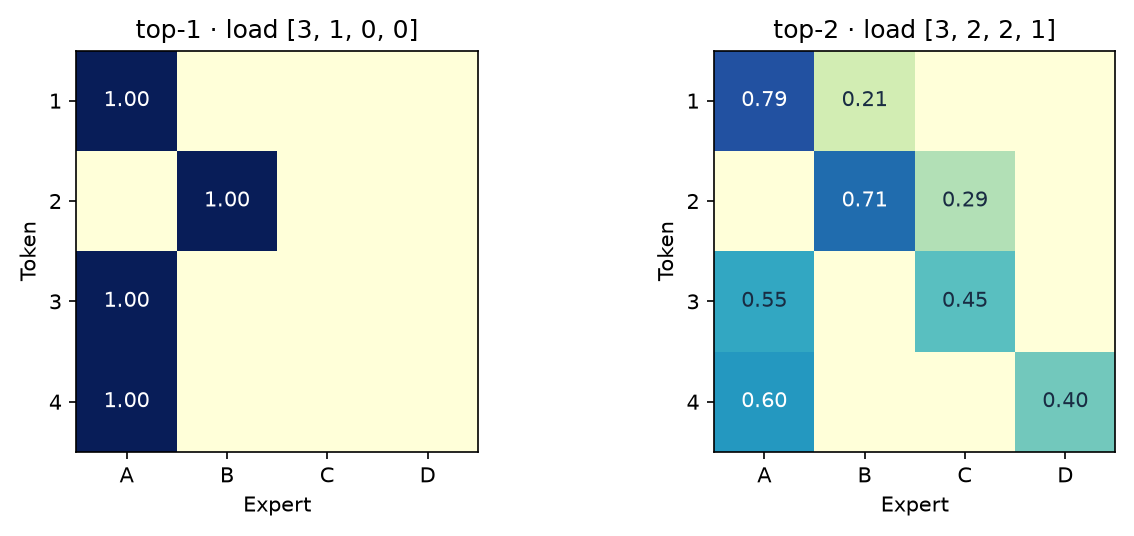


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w12a/course/notion/w12a/assets/07-routing.png)


In [ ]:
def causal_mask(tokens=8, window=None):
    """Visible positions for each query, including its own position."""
    if tokens < 1 or window is not None and window < 1:
        raise ValueError("Use a positive token count and window.")
    offset = np.arange(tokens)[:, None] - np.arange(tokens)[None, :]
    return (offset >= 0) & (offset < (tokens if window is None else window))

def route_experts(logits, top_k=2):
    """Select top-k per token and normalize weights across selected experts."""
    logits = np.asarray(logits, dtype=float)
    if logits.ndim != 2 or not np.isfinite(logits).all() or not 1 <= top_k <= logits.shape[1]:
        raise ValueError("Use a finite token×expert matrix and a valid top_k.")
    selected = np.argsort(-logits, axis=1, kind="stable")[:, :top_k]
    active_logits = np.take_along_axis(logits, selected, axis=1)
    weights = np.exp(active_logits - active_logits.max(axis=1, keepdims=True))
    weights /= weights.sum(axis=1, keepdims=True)
    load = np.bincount(selected.ravel(), minlength=logits.shape[1])
    return selected, weights, load


In [ ]:
k, window = 2, 3
selected, weights, load = route_experts(ROUTER_EXAMPLE,k)
print("전문가 인덱스",selected)
print("선택된 점수의 정규화",weights)
print("부하",load,"· 마지막 행의 가시 위치",np.flatnonzero(causal_mask(8,window)[-1]))


### B2 · 창을 3→2, 전문가 수를 2→1로 바꾸세요
마지막 위치에서 어떤 키를 더 이상 볼 수 없나요? 전문가별 호출량과 각 토큰에서 가중치 합을 확인하세요.


## 10.4–10.6 작은 숫자로 시스템 설계하기

가중치 양자화는 표현 격자에 값을 맞춥니다. 추측 디코딩은 작은 모델이 낸 토큰 후보를 큰 모델이 검증해 승인 여부를 정합니다. 재표본화의 전체 알고리즘은 강의노트에 설명하고, 여기서는 한 후보의 승인 줄을 따라갑니다.

아래의 단순 길이·중복 필터가 실제 축제 안내 문구를 줄입니다. 행사를 알려주는 짧은 문구가 빠지는지 확인하세요. 이후 자주 바뀌는 일정의 근거는 어디에서 가져올지 결정합니다.


In [ ]:
def symmetric_round(values, bits=4):
    """Round to a signed grid using a single absmax scale and dequantize."""
    values = np.asarray(values, dtype=float)
    if bits not in (4, 8) or not np.isfinite(values).all():
        raise ValueError("Use 4 or 8 bits and finite values.")
    max_code = (1 << (bits - 1)) - 1
    scale = np.abs(values).max() / max_code
    if scale == 0:
        return np.zeros_like(values, dtype=int), scale, values.copy()
    codes = np.round(values / scale).astype(int)
    return codes, float(scale), codes * scale

def verify_candidate(target_prob, draft_prob, uniform):
    """One acceptance decision in distribution-preserving speculative sampling."""
    if not 0 <= target_prob <= 1 or not 0 < draft_prob <= 1 or not 0 <= uniform < 1:
        raise ValueError("Probabilities must be valid and the proposed token has q > 0.")
    acceptance = min(1.0, target_prob / draft_prob)
    return acceptance, uniform < acceptance

def filter_examples(rows, min_words=4):
    """Use a transparent toy quality filter followed by exact deduplication."""
    seen = set()
    trace = []
    for row in rows:
        key = " ".join(row.casefold().split())
        if len(key.split()) < min_words:
            reason = "too short"
        elif key in seen:
            reason = "duplicate"
        else:
            reason = "kept"
            seen.add(key)
        trace.append((row, reason))
    return trace


In [ ]:
values = np.array([-1.27,-.53,-.26,.07,.48,1.27])
for bits in [4,8]:
    ids, scale, decoded = symmetric_round(values,bits)
    print(bits, scale, ids, "MSE",np.mean((values-decoded)**2))
print("승인",verify_candidate(.2,.5,.35),"· 거절",verify_candidate(.2,.5,.6))
corpus = ["Doors open at ten", "Doors  open at TEN", "Rain venue changed",
          "Ask the blue booth for help"]
print(*filter_examples(corpus), sep="\n")


### B3 · 필터가 버리는 근거
최소 단어 수를 4에서 3으로 낮춰 어떤 문장이 복구되는지 찾으세요. 실시간 장소 변경 공지를 서비스에 제공할 방법을 고르세요.


## 10.7–10.10 같은 사진을 읽고, 실제 영상의 시간 축을 보기

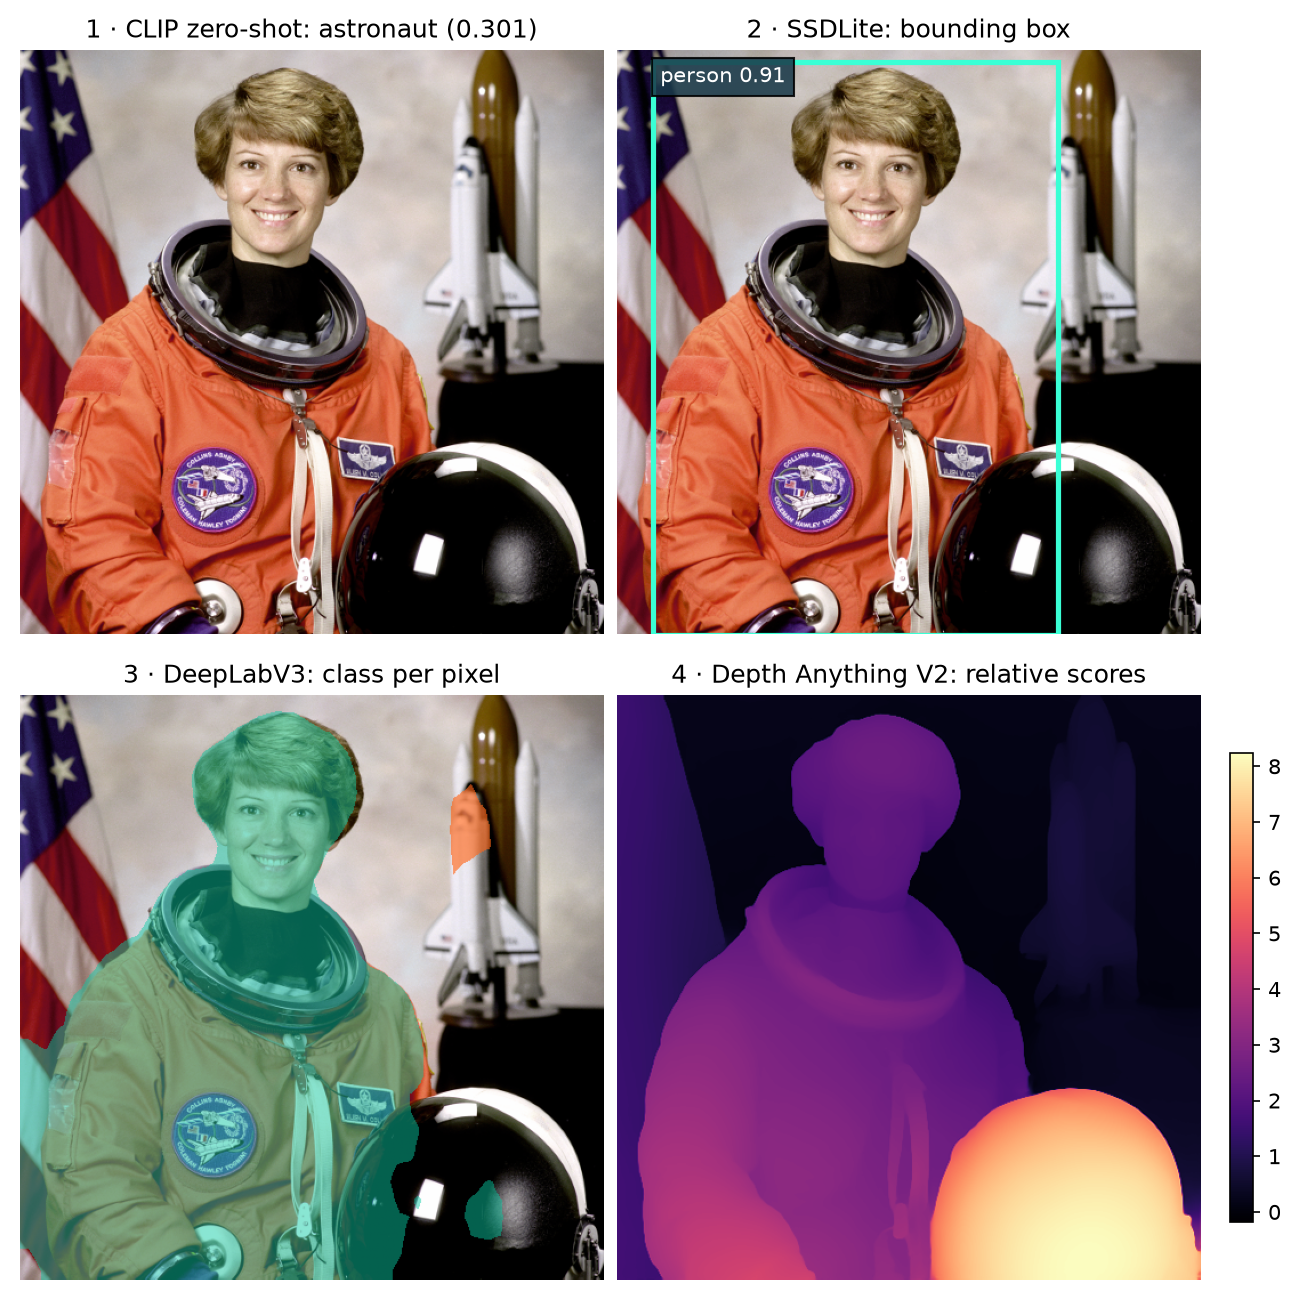

NASA 공개 사진의 모델 실제 실행 결과입니다. CLIP은 후보 문장을 비교하고, 탐지기는 상자, 분할은 마스크, 상대 깊이는 픽셀마다 근거리·원거리를 비교할 단서를 냅니다. 아래 코드는 실제 CLIP 임베딩 기록에서 코사인 점수를 다시 계산합니다.

**3D 시점 이동.** [3D Gaussian Splatting 원저자 시연](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/)에서 카메라가 옆으로 움직일 때 가려져 있던 물체가 어떻게 나타나는지 관찰합니다.

**비디오의 시간 일관성.** [Sora 기술 보고서의 실제 사례](https://openai.com/index/video-generation-models-as-world-simulators/#discussion)에서 물체 상태, 가려짐 뒤 재등장, 연속 프레임의 형태 변화를 확인하세요. [Mochi 제작자 예시](https://github.com/genmoai/mochi)에서도 고정한 물체를 한 가지 따라갑니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w12a/course/notion/w12a/assets/10-vision.png)


In [ ]:
def image_text_scores(image_embedding, text_embeddings):
    """Cosine scores for a fixed image and each candidate caption."""
    image_embedding = np.asarray(image_embedding, dtype=float).reshape(-1)
    text_embeddings = np.asarray(text_embeddings, dtype=float)
    denominator = np.linalg.norm(text_embeddings, axis=1) * np.linalg.norm(image_embedding)
    if not np.isfinite(denominator).all() or np.any(denominator == 0):
        raise ValueError("Cosine similarity requires finite nonzero embeddings.")
    return (text_embeddings @ image_embedding) / denominator


In [ ]:
with ASSET.joinpath("clip-features.npz").open("rb") as stream:
    clip = dict(np.load(stream,allow_pickle=False))
keep = [0, 1, 2, 3]
similarity = image_text_scores(clip["image"],clip["text"][keep])
display(list(zip(clip["prompts"][keep].tolist(),similarity.round(3).tolist())))
text_records = json.loads(ASSET.joinpath("vision-text.json").read_text(encoding="utf-8"))
print("BLIP 캡션",text_records["blip"]["answer"])
print("SmolVLM 질문",text_records["smolvlm"]["question"],"· 답",text_records["smolvlm"]["answer"])
display(YouTubeVideo("T_kXY43VZnk", width=560, height=315))


### B4 · 후보 목록을 바꾸고 예측을 점검하세요
후보 0번을 제외하면 어떤 후보가 올라오나요? BLIP 캡션에서 사진 출처의 설명과 대조할 수 있는 표현을 찾아보세요.


## 10.11 커뮤니티 자료로 검증하기

원저자의 모델 카드 또는 프로젝트를 하나 고릅니다. 입력·출력·실행 환경·라이선스·관찰한 한계를 한 줄씩 기록하세요. 예제 파일 하나와 재현에 필요한 버전 하나를 찾습니다.

아래 앱에서 선호 응답·전문가 수·가시 창을 바꿉니다. 위에서 편집한 함수가 앱에서도 그대로 계산되는지 확인하세요. 브라우저 앱을 열려면 마지막 줄의 주석을 지웁니다.


In [ ]:
app = build_frontier_app(loss_fn=preference_loss,routing_fn=route_experts,mask_fn=causal_mask)
figure, metrics=app.w12a_explore(chosen,k,window)
show_plot(figure)
display(metrics)
# app.launch(share=IN_COLAB, inline=False, prevent_thread_lock=True)


In [ ]:
assert preference_loss(policy,reference,0)[0] < preference_loss(policy,reference,1)[0]
assert np.isclose(weights.sum(axis=1),1).all() and load.sum() == 4*k
assert causal_mask().sum()==36 and causal_mask(8,3).sum()==21
assert abs(np.mean((values-symmetric_round(values,8)[2])**2)) < np.mean((values-symmetric_round(values,4)[2])**2)
assert clip["text"].shape==(4,512) and np.isfinite(similarity).all()
assert text_records["blip"]["answer"] and text_records["smolvlm"]["answer"]
modified = build_frontier_app(loss_fn=lambda p,r,c:preference_loss(p,r,c,beta=1))
assert np.isclose(modified.w12a_explore(0,1,2)[1]["signed logit"],.7)
print("W12A_FRONTIER_RUNTIME_PASS", metrics)
